Trying to figure out if it's better to just mask RTN pixels

In [246]:
import numpy as np
import matplotlib.pyplot as plt
import math
from math import erf, sqrt
from scipy import special, integrate
from photutils.aperture import CircularAperture

In [247]:
def gaussian_ensq_energy(half_width, sigma_x, sigma_y):
    '''Returns the energy in square of half-width p centered on a Gaussian PSF.

    Parameters
    ----------
    half_width : float
        The half-width of the square, in units of um.
    sigma_x : float
        The standard deviation of the Gaussian in the x direction, in um.
    sigma_y : float
        The standard deviation of the Gaussian in the y direction, in um.

    Returns
    -------
    pix_fraction : float
        The fraction of the light that hits the square.
    '''
    arg_x = half_width / np.sqrt(2) / sigma_x
    arg_y = half_width / np.sqrt(2) / sigma_y
    pix_fraction = special.erf(arg_x) * special.erf(arg_y)
    return pix_fraction

def gaussian_psf(num_pix, resolution, pix_size, mu, sigma):
    '''Return an x-y grid with a Gaussian disk evaluated at each point.

    Parameters
    ----------
    num_pix : int
        The number of pixels in the subarray.
    resolution : int
        The number of subpixels per pixel in the subarray.
    pix_size : float
        The size of each pixel in the subarray, in microns.
    mu : array-like
        The mean of the Gaussian, in microns.
    Sigma : array-like
        The covariance matrix of the Gaussian, in microns^2.

    Returns
    -------
    gaussian : array-like
        The Gaussian PSF evaluated at each point in the subarray,
        normalized to have a total amplitude of the fractional energy
        ensquared in the subarray.
    '''
    grid_points = num_pix * resolution
    x = np.linspace(-num_pix / 2.0, num_pix / 2.0, grid_points) * pix_size
    y = np.linspace(-num_pix / 2.0, num_pix / 2.0, grid_points) * pix_size
    x, y = np.meshgrid(x, y)
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y

    sigma_inv = np.linalg.inv(sigma)
    # This einsum call calculates (x-mu)T.Sigma-1.(x-mu) in a vectorized
    # way across all the input variables.
    arg = np.einsum('...k,kl,...l->...', pos-mu, sigma_inv, pos-mu)
    # Determine the fraction of the light that hits the entire subarray
    array_p = num_pix / 2 * pix_size
    subarray_fraction = gaussian_ensq_energy(array_p, np.sqrt(sigma[0][0]), np.sqrt(sigma[1][1]))
    # Normalize the PSF to have a total amplitude of subarray_fraction
    gaussian = np.exp(-arg / 2)
    normalize = subarray_fraction / gaussian.sum()
    return gaussian * normalize

In [248]:
def get_snr_options(frame, frac_rtn_pix, sigma_no_rtn, sigma_rtn, random_seed=42, lambda_max=10, fixed_aper_radius=None):
    # Get optimal aperture for all cases, or use fixed circular aperture
    np.random.seed(random_seed)
    num_pix = frame.shape[0]
    signal_rtn_uncorrected = 0
    signal_rtn_masked = 0
    signal_rtn_corrected = 0
    noise_rtn_uncorrected = 0
    noise_rtn_masked = 0
    noise_rtn_corrected = 0
    snr_rtn_uncorrected = 0
    snr_rtn_masked = 0
    snr_rtn_corrected = 0
    n_aper_uncorrected = 0
    n_aper_masked = 0
    n_aper_corrected = 0
    uncorrected_aper_found = False
    masked_aper_found = False
    corrected_aper_found = False
    # Build pixel mask for fixed aperture if specified
    if fixed_aper_radius is not None:
        y_grid, x_grid = np.indices(frame.shape)
        r_grid = np.sqrt((x_grid - num_pix / 2) ** 2 + (y_grid - num_pix / 2) ** 2)
        aper_mask = r_grid <= fixed_aper_radius
    func_grid = frame.copy()
    for i in range(num_pix ** 2):
        imax, jmax = np.unravel_index(func_grid.argmax(), func_grid.shape)
        max_sig_remaining = frame[imax, jmax]
        func_grid[imax, jmax] = -1
        # Skip pixels outside fixed aperture if specified
        if fixed_aper_radius is not None and not aper_mask[imax, jmax]:
            continue
        # Randomly decide if this pixel is RTN-affected
        if np.random.rand() < frac_rtn_pix:
            is_rtn = True
            pix_read_noise = sigma_rtn
        else:
            is_rtn = False
            pix_read_noise = sigma_no_rtn
        # Uncorrected option
        if not uncorrected_aper_found:
            signal_rtn_uncorrected += max_sig_remaining
            noise_rtn_uncorrected = np.sqrt(noise_rtn_uncorrected ** 2 + max_sig_remaining + pix_read_noise ** 2)
            new_snr_rtn_uncorrected = signal_rtn_uncorrected / noise_rtn_uncorrected
            if fixed_aper_radius is None and new_snr_rtn_uncorrected < snr_rtn_uncorrected:
                # uncorrected_aper_found = True
                pass
            else:
                snr_rtn_uncorrected = new_snr_rtn_uncorrected
                n_aper_uncorrected += 1
        # Masked option
        if not masked_aper_found:
            if is_rtn:
                pass
            else:
                signal_rtn_masked += max_sig_remaining
                noise_rtn_masked = np.sqrt(noise_rtn_masked ** 2 + max_sig_remaining + pix_read_noise ** 2)
                new_snr_rtn_masked = signal_rtn_masked / noise_rtn_masked
                if fixed_aper_radius is None and new_snr_rtn_masked < snr_rtn_masked:
                    masked_aper_found = True
                else:
                    snr_rtn_masked = new_snr_rtn_masked
                    n_aper_masked += 1
        # Corrected option
        if not corrected_aper_found:
            if is_rtn:
                # Interpolate between sigma_no_rtn and sigma_rtn based on lambda_max
                if max_sig_remaining >= lambda_max:
                    pix_read_noise = sigma_rtn
                else:
                    pix_read_noise = sigma_no_rtn + (sigma_rtn - sigma_no_rtn) * (max_sig_remaining / lambda_max)
            else:
                pix_read_noise = sigma_no_rtn
            signal_rtn_corrected += max_sig_remaining
            noise_rtn_corrected = np.sqrt(noise_rtn_corrected ** 2 + max_sig_remaining + pix_read_noise ** 2)
            new_snr_rtn_corrected = signal_rtn_corrected / noise_rtn_corrected
            if fixed_aper_radius is None and new_snr_rtn_corrected < snr_rtn_corrected:
                # corrected_aper_found = True
                pass
            else:
                snr_rtn_corrected = new_snr_rtn_corrected
                n_aper_corrected += 1
        if (uncorrected_aper_found and
            masked_aper_found and
            corrected_aper_found):
            break
    return {'signal_uncorrected': signal_rtn_uncorrected,
            'snr_uncorrected': snr_rtn_uncorrected,
            'n_aper_uncorrected': n_aper_uncorrected,
            'signal_masked': signal_rtn_masked,
            'snr_masked': snr_rtn_masked,
            'n_aper_masked': n_aper_masked,
            'signal_corrected': signal_rtn_corrected,
            'snr_corrected': snr_rtn_corrected,
            'n_aper_corrected': n_aper_corrected}

In [273]:
def get_snr_options_mc(frame, frac_rtn_pix, sigma_no_rtn, sigma_rtn, n_trials=100, lambda_max=10, fixed_aper_radius=None):
    snr_uncorrected_list = np.zeros(n_trials)
    snr_masked_list = np.zeros(n_trials)
    snr_corrected_list = np.zeros(n_trials)
    aper_size_masked_list = np.zeros(n_trials)
    aper_size_corrected_list = np.zeros(n_trials)
    for i in range(n_trials):
        results_dict = get_snr_options(frame, frac_rtn_pix, sigma_no_rtn, sigma_rtn, random_seed=42 + i, lambda_max=lambda_max, fixed_aper_radius=fixed_aper_radius)
        snr_uncorrected_list[i] = results_dict['snr_uncorrected']
        snr_masked_list[i] = results_dict['snr_masked']
        snr_corrected_list[i] = results_dict['snr_corrected']
        aper_size_masked_list[i] = results_dict['n_aper_masked']
        aper_size_corrected_list[i] = results_dict['n_aper_corrected']
    # Compute per-trial ratios for quartiles
    ratio_masked = snr_masked_list / snr_uncorrected_list
    ratio_corrected = snr_corrected_list / snr_uncorrected_list
    return {'snr_uncorrected_avg': np.mean(snr_uncorrected_list),
            'snr_masked_avg': np.mean(snr_masked_list),
            'snr_corrected_avg': np.mean(snr_corrected_list),
            'ratio_masked_avg': np.mean(ratio_masked),
            'ratio_masked_q1': np.percentile(ratio_masked, 10),
            'ratio_masked_q3': np.percentile(ratio_masked, 90),
            'ratio_corrected_avg': np.mean(ratio_corrected),
            'ratio_corrected_q1': np.percentile(ratio_corrected, 10),
            'ratio_corrected_q3': np.percentile(ratio_corrected, 90),
            'n_aper_masked_avg': np.mean(aper_size_masked_list),
            'n_aper_corrected_avg': np.mean(aper_size_corrected_list)}

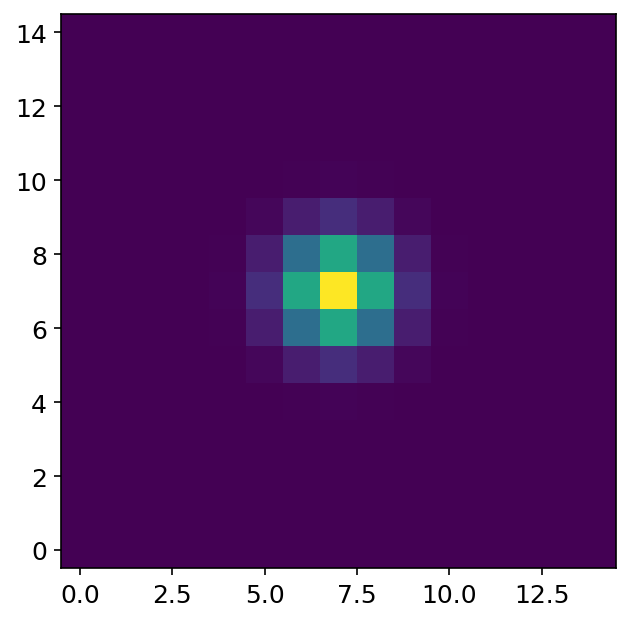

Mean electrons per pixel within 1 FWHM: 1.02


In [274]:
num_pix = 15
pix_size = 5
mu = [0, 0]
fwhm = 2.5 * pix_size
sigma = (fwhm / (2 * math.sqrt(2 * math.log(2))))
sigma_arr = [[sigma ** 2, 0], [0, sigma ** 2]]
psf = gaussian_psf(num_pix, resolution=1, pix_size=pix_size, mu=mu,
                   sigma=sigma_arr)
plt.imshow(psf, origin='lower', cmap='viridis')
plt.show()
max_phot = 3  # Max electrons per frame in central pixel
multiplier = max_phot / np.max(psf)
frame = psf * multiplier
# Get average flux within 1 FWHM of the center
y, x = np.indices(frame.shape)
r = np.sqrt((x - num_pix / 2) ** 2 + (y - num_pix / 2) ** 2)
mean_val_e_per_pix = np.round(frame[r < fwhm / pix_size].mean(),2)
print("Mean electrons per pixel within 1 FWHM:", mean_val_e_per_pix)

In [314]:
frac_rtn_pix = 0.05  # Fraction of pixels affected by RTN
sigma_no_rtn = 1.2
sigma_rtn = 3
lambda_max = 5
results_dict = get_snr_options(frame, frac_rtn_pix, sigma_no_rtn, sigma_rtn, random_seed=45, lambda_max=lambda_max, fixed_aper_radius=2)
print(results_dict['signal_uncorrected'], results_dict['snr_uncorrected'], results_dict['n_aper_uncorrected'])
print(results_dict['signal_masked'], results_dict['snr_masked'], results_dict['n_aper_masked'])
print(results_dict['signal_corrected'], results_dict['snr_corrected'], results_dict['n_aper_corrected'])
print(results_dict['snr_masked'] / results_dict['snr_uncorrected'], results_dict['snr_corrected'] / results_dict['snr_uncorrected'])

14.714327009961009 2.3396096483842714 12
13.630920439306253 2.5108937341453132 11
14.714327009961009 2.5582393316846805 12
1.0732105400058212 1.0934470771444262


In [276]:
rtn_frac_list = np.linspace(0, 0.1, 15)
snr_ratio_masked = np.zeros_like(rtn_frac_list)
snr_ratio_corrected = np.zeros_like(rtn_frac_list)
aper_size_masked = np.zeros_like(rtn_frac_list)
aper_size_corrected = np.zeros_like(rtn_frac_list)
for i, frac_rtn_pix in enumerate(rtn_frac_list):
    results_dict = get_snr_options_mc(frame, frac_rtn_pix, sigma_no_rtn, sigma_rtn, n_trials=200, lambda_max=lambda_max, fixed_aper_radius=fwhm)
    snr_ratio_masked[i] = results_dict['snr_masked_avg'] / results_dict['snr_uncorrected_avg']
    snr_ratio_corrected[i] = results_dict['snr_corrected_avg'] / results_dict['snr_uncorrected_avg']
    aper_size_masked[i] = results_dict['n_aper_masked_avg']
    aper_size_corrected[i] = results_dict['n_aper_corrected_avg']

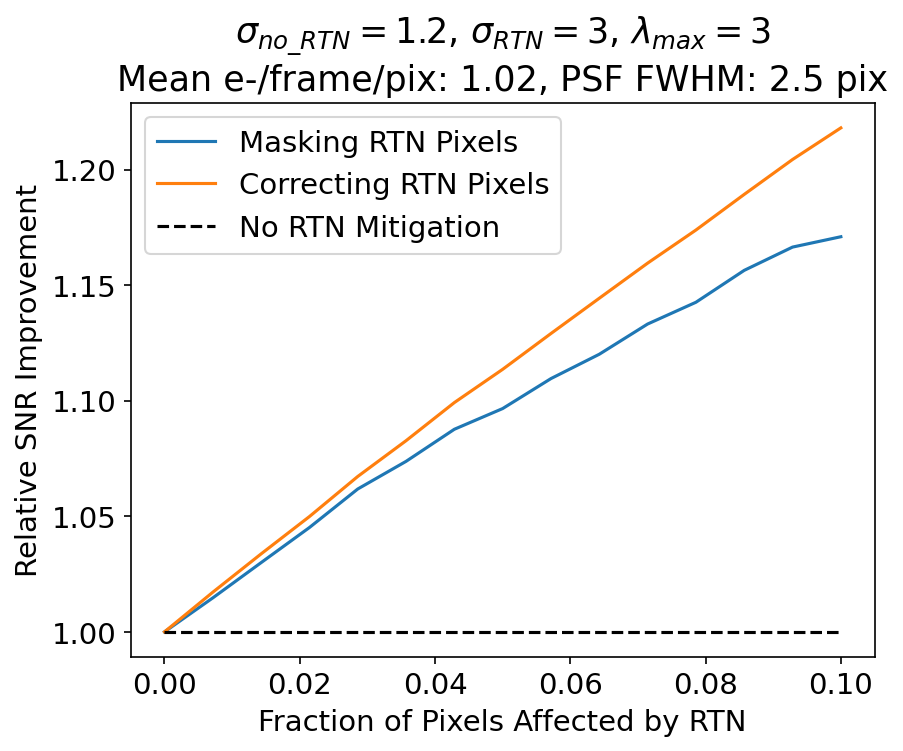

In [277]:
plt.rcParams.update({'font.size': 14})
plt.plot(rtn_frac_list, snr_ratio_masked, label='Masking RTN Pixels')
plt.plot(rtn_frac_list, snr_ratio_corrected, label='Correcting RTN Pixels')
plt.plot(rtn_frac_list, np.ones_like(rtn_frac_list), 'k--', label='No RTN Mitigation')
plt.xlabel("Fraction of Pixels Affected by RTN")
plt.ylabel("Relative SNR Improvement")
plt.title(r'$\sigma_{no\_RTN}=$' + f'{sigma_no_rtn}, ' +
          r'$\sigma_{RTN}=$' + f'{sigma_rtn}' + 
          r', $\lambda_{max}=$' + f'{lambda_max}' +
          '\nMean e-/frame/pix: ' + f'{mean_val_e_per_pix}' + 
          ', PSF FWHM: ' + f'{fwhm / pix_size} pix')
plt.legend()
plt.show()

In [322]:
# SNR improvement vs mean e-/frame/pix for three PSF FWHMs
fwhm_pix_list = [1.5, 2.5]
rtn_frac_list_3 = [0.02, 0.05, 0.1]
mean_e_targets = np.logspace(np.log10(0.3), np.log10(30), 50)

# Store results: dict keyed by (fwhm_pix, frac_rtn)
#   -> (mean_e_targets, masked_ratio, masked_q1, masked_q3, corrected_ratio, corrected_q1, corrected_q3)
sweep_results = {}
# Store total-source-electrons scale factor per FWHM:
#   total_e = mean_e * total_e_scale[fwhm_pix]
total_e_scale = {}

for fwhm_pix in fwhm_pix_list:
    fwhm_um = fwhm_pix * pix_size
    sig = fwhm_um / (2 * math.sqrt(2 * math.log(2)))
    sig_arr = [[sig ** 2, 0], [0, sig ** 2]]
    psf_local = gaussian_psf(num_pix, resolution=1, pix_size=pix_size, mu=mu,
                             sigma=sig_arr)
    # Compute mean PSF value within 1 FWHM for scaling
    y_grid, x_grid = np.indices(psf_local.shape)
    r_grid = np.sqrt((x_grid - num_pix / 2) ** 2 + (y_grid - num_pix / 2) ** 2)
    psf_mean_fwhm = psf_local[r_grid < fwhm_pix].mean()
    # total_e = (target_mean / psf_mean_fwhm) * psf_local.sum()
    total_e_scale[fwhm_pix] = psf_local.sum() / psf_mean_fwhm

    for frac_rtn in rtn_frac_list_3:
        masked_ratio_arr = np.zeros(len(mean_e_targets))
        masked_q1_arr = np.zeros(len(mean_e_targets))
        masked_q3_arr = np.zeros(len(mean_e_targets))
        corrected_ratio_arr = np.zeros(len(mean_e_targets))
        corrected_q1_arr = np.zeros(len(mean_e_targets))
        corrected_q3_arr = np.zeros(len(mean_e_targets))

        for j, target_mean in enumerate(mean_e_targets):
            mult = target_mean / psf_mean_fwhm
            frame_local = psf_local * mult

            results = get_snr_options_mc(frame_local, frac_rtn, sigma_no_rtn,
                                         sigma_rtn, n_trials=400, lambda_max=lambda_max, fixed_aper_radius=fwhm_pix)
            masked_ratio_arr[j] = results['ratio_masked_avg']
            masked_q1_arr[j] = results['ratio_masked_q1']
            masked_q3_arr[j] = results['ratio_masked_q3']
            corrected_ratio_arr[j] = results['ratio_corrected_avg']
            corrected_q1_arr[j] = results['ratio_corrected_q1']
            corrected_q3_arr[j] = results['ratio_corrected_q3']

        sweep_results[(fwhm_pix, frac_rtn)] = (mean_e_targets, masked_ratio_arr, masked_q1_arr, masked_q3_arr,
                                                corrected_ratio_arr, corrected_q1_arr, corrected_q3_arr)
        print(f"Done: FWHM={fwhm_pix} pix, RTN frac={frac_rtn}")

print("\nTotal e- scale factors:", {k: f'{v:.1f}' for k, v in total_e_scale.items()})

Done: FWHM=1.5 pix, RTN frac=0.02
Done: FWHM=1.5 pix, RTN frac=0.05
Done: FWHM=1.5 pix, RTN frac=0.1
Done: FWHM=2.5 pix, RTN frac=0.02
Done: FWHM=2.5 pix, RTN frac=0.05
Done: FWHM=2.5 pix, RTN frac=0.1

Total e- scale factors: {1.5: '5.8', 2.5: '18.1'}


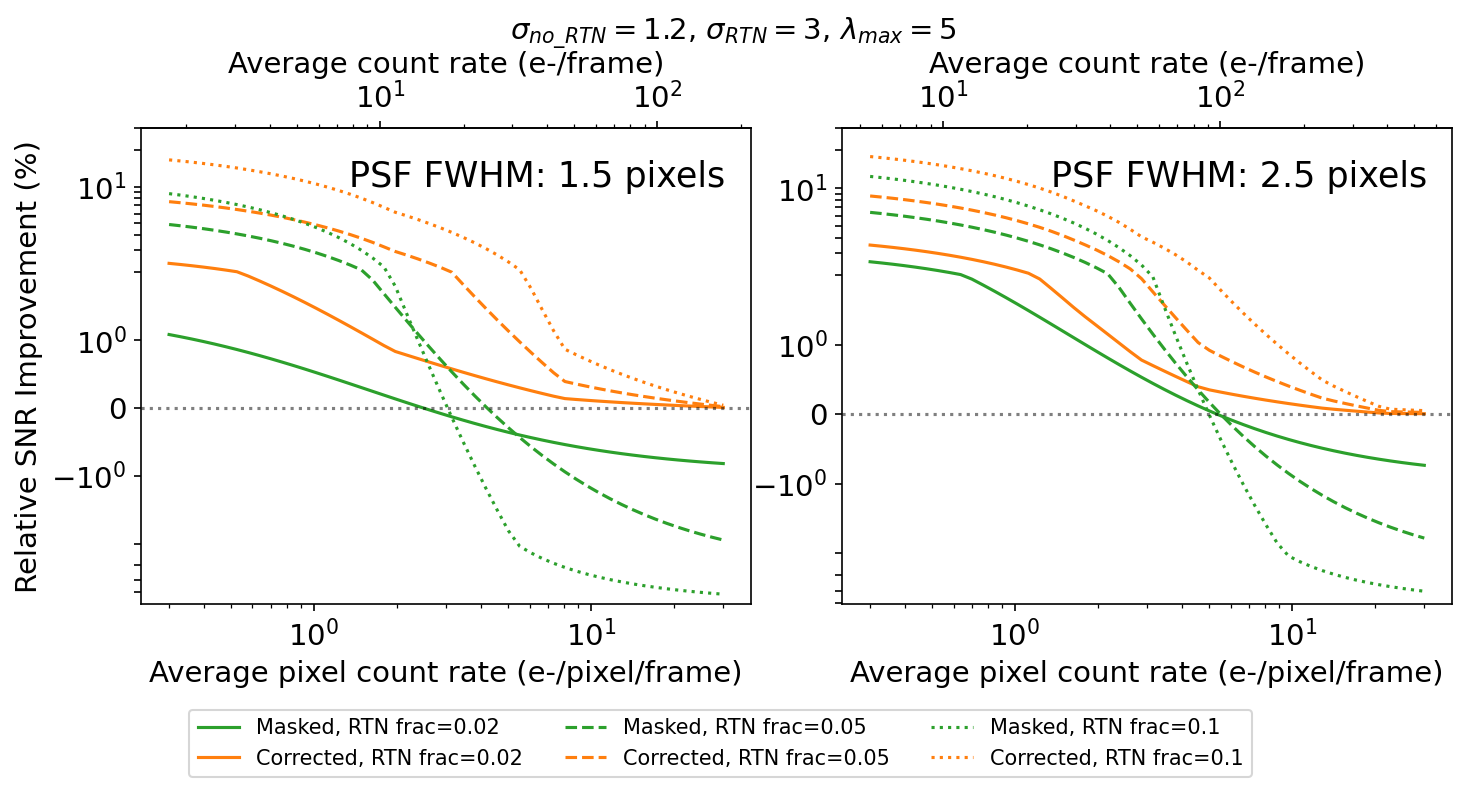

In [325]:
linestyles = ['-', '--', ':']
plt.rcParams.update({'font.size': 14})
fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=False)
fig.subplots_adjust(wspace=0.05)

for ax_idx, fwhm_pix in enumerate(fwhm_pix_list):
    ax = axes[ax_idx]
    for k, frac_rtn in enumerate(rtn_frac_list_3):
        mean_e, masked_ratio, masked_q1, masked_q3, corrected_ratio, corrected_q1, corrected_q3 = sweep_results[(fwhm_pix, frac_rtn)]
        masked_pct = (masked_ratio - 1) * 100
        masked_q1_pct = (masked_q1 - 1) * 100
        masked_q3_pct = (masked_q3 - 1) * 100
        corrected_pct = (corrected_ratio - 1) * 100
        corrected_q1_pct = (corrected_q1 - 1) * 100
        corrected_q3_pct = (corrected_q3 - 1) * 100

        ax.plot(mean_e, masked_pct, color='C2', linestyle=linestyles[k],
                label=f'Masked, RTN frac={frac_rtn}')
        ax.plot(mean_e, corrected_pct, color='C1', linestyle=linestyles[k],
                label=f'Corrected, RTN frac={frac_rtn}')
        # if k == 2:
        #     ax.fill_between(mean_e, masked_q1_pct, masked_q3_pct,
        #                 color='C2', alpha=0.1)

        #     ax.fill_between(mean_e, corrected_q1_pct, corrected_q3_pct,
        #                 color='C1', alpha=0.1)

    ax.axhline(0, color='k', linestyle=':', alpha=0.5)
    ax.set_xlabel('Average pixel count rate (e-/pixel/frame)')
    ax.set_xscale('log')
    ax.set_yscale('symlog')
    ax.set_yticks([-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20, 30])
    ax.set_title(f'PSF FWHM: {fwhm_pix} pixels', y=0.85, x=0.65)
    if ax_idx == 0:
        ax.set_ylabel('Relative SNR Improvement (%)')

    # Secondary x-axis: total average source electrons
    scale = total_e_scale[fwhm_pix]
    secax = ax.secondary_xaxis('top', functions=(lambda x, s=scale: x * s,
                                                  lambda x, s=scale: x / s))
    secax.set_xlabel('Average count rate (e-/frame)')

axes[1].legend(bbox_to_anchor=(-0.2, -0.2), loc='upper center', ncol=3, fontsize=10)
fig.suptitle(r'$\sigma_{no\_RTN}=$' + f'{sigma_no_rtn}, ' +
             r'$\sigma_{RTN}=$' + f'{sigma_rtn}' + r', $\lambda_{max}=$' + f'{lambda_max}',
             fontsize=14, y=0.93)
plt.tight_layout()
fig.subplots_adjust(wspace=0.15)
plt.show()

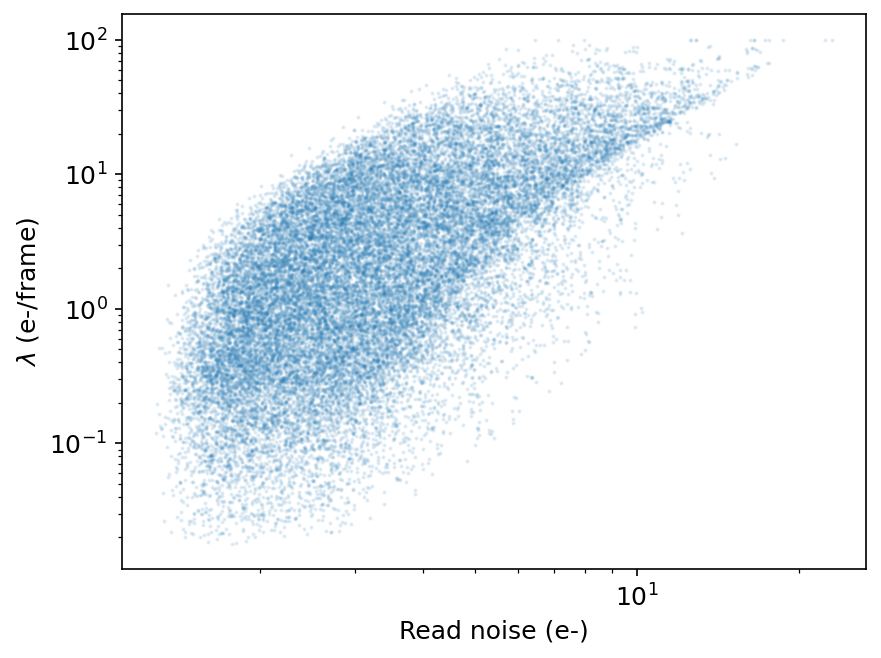

In [256]:
from astropy.io import fits
lambda_array = fits.getdata('/Users/layden/Library/CloudStorage/Box-Box/Scientific CMOS - MKI ONLY (might contain EAR; ITAR)/Random_Telegraph_Noise/rtn_biases/rtn_fits_output/rtn_params.fits')[-1]
rn_array = fits.getdata('/Users/layden/Library/CloudStorage/Box-Box/Scientific CMOS - MKI ONLY (might contain EAR; ITAR)/Random_Telegraph_Noise/rtn_biases/rtn_fits_output/read_noise_frame.fits')
lambda_list = lambda_array[lambda_array is not np.nan]
rn_list = rn_array[lambda_array is not np.nan]
plt.scatter(rn_list, lambda_list, s=1, alpha=0.1)
plt.xscale('log')
plt.yscale('log')
plt.ylabel(r'$\lambda$ (e-/frame)')
plt.xlabel('Read noise (e-)')
plt.show()